In [1]:
import polars as pl
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import statsmodels.api as sm
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

DATA_RAW      = Path("../data/raw/quotes_data_2024_2025_2026.csv")   # adjust filename
PROCESSED_DIR = Path("../data/processed")

PLOT_CFG = dict(
    width=1200, height=700,
    margin=dict(l=50, r=50, t=50, b=120),
    legend=dict(
        orientation="h", yanchor="top",
        y=-0.15, xanchor="center", x=0.5,
        font=dict(size=10)
    )
)

# ── load raw ───────────────────────────────────────────────────────
df_raw = pl.read_csv(DATA_RAW, try_parse_dates=False, infer_schema_length=10000)

print(f"Raw shape: {df_raw.shape}")
print(f"\nColumns: {df_raw.columns}")
print(f"\nQUOTE_STATUS_NM distribution:")
print(df_raw["QUOTE_STATUS_NM"].value_counts().sort("count", descending=True))
print(f"\nORDER_TYPE_TXT distribution:")
print(df_raw["ORDER_TYPE_TXT"].value_counts().sort("count", descending=True))
print(f"\nDEP_MACRO_REGION distribution:")
print(df_raw["DEP_MACRO_REGION"].value_counts().sort("count", descending=True))
print(f"\nFLEET_NAME distribution:")
print(df_raw["FLEET_NAME"].value_counts().sort("count", descending=True))
print(f"\nUnique QUOTE_LEG_IDs: {df_raw['QUOTE_LEG_ID'].n_unique()}")
print(f"Total rows:           {len(df_raw)}")
print(f"Duplication factor:   {len(df_raw)/df_raw['QUOTE_LEG_ID'].n_unique():.2f}x")

Raw shape: (220619, 26)

Columns: ['QUOTE_LEG_ID', 'GV_ORDER_ID', 'LEG_ID', 'QUOTE_CREATE_DTTM', 'QUOTE_STATUS_NM', 'TAIL_NO', 'FLEET_NAME', 'REVENUE', 'DEP_ICAO_CD', 'ARR_ICAO_CD', 'EST_DEPARTURE_DTTM', 'SCHDL_DEPARTURE_DTTM', 'EST_ARVL_DTTM', 'SCHDL_ARVL_DTTM', 'TENANT_CD', 'ORDER_TYPE_TXT', 'ORDER_STATUS_TXT', 'CONTRACT_DETAIL_ID', 'EST_FLIGHT_TIME_VAL', 'DEP_MACRO_REGION', 'DEP_MICRO_REGION', 'ARR_MACRO_REGION', 'ARR_MICRO_REGION', 'MEMBERSHIP_TYPE', 'MEMBERSHIP_SUPER_CATEGORY', 'MEMBERSHIP_SUB_CATEGORY']

QUOTE_STATUS_NM distribution:
shape: (5, 2)
┌─────────────────┬────────┐
│ QUOTE_STATUS_NM ┆ count  │
│ ---             ┆ ---    │
│ str             ┆ u32    │
╞═════════════════╪════════╡
│ Cancelled       ┆ 129287 │
│ Quoted          ┆ 70793  │
│ Confirmed       ┆ 13980  │
│ Unconfirmed     ┆ 5375   │
│ Option          ┆ 1184   │
└─────────────────┴────────┘

ORDER_TYPE_TXT distribution:
shape: (5, 2)
┌─────────────────┬────────┐
│ ORDER_TYPE_TXT  ┆ count  │
│ ---             ┆

In [2]:
df_filtered = (
    df_raw
    .with_columns([
        # quote date = when demand was expressed
        pl.col("QUOTE_CREATE_DTTM")
          .str.slice(0, 10)
          .str.to_date(format="%Y-%m-%d")
          .alias("quote_date"),
        # departure date = what they want
        pl.col("SCHDL_DEPARTURE_DTTM")
          .str.slice(0, 10)
          .str.to_date(format="%Y-%m-%d")
          .alias("dep_date"),
    ])
    # training window
    .filter(pl.col("quote_date").dt.year().is_in([2024, 2025]))
    # NREG US fleet + region
    .filter(
        pl.col("DEP_MACRO_REGION").eq("North America") &
        pl.col("FLEET_NAME").is_in(["Challenger 300", "Challenger 350"])
    )
)

print(f"After filter shape: {df_filtered.shape}")
print(f"Quote date range: {df_filtered['quote_date'].min()} → {df_filtered['quote_date'].max()}")
print(f"Dep date range:   {df_filtered['dep_date'].min()} → {df_filtered['dep_date'].max()}")
print(f"\nUnique QUOTE_LEG_IDs after filter: {df_filtered['QUOTE_LEG_ID'].n_unique()}")

After filter shape: (182965, 28)
Quote date range: 2024-01-01 → 2025-12-31
Dep date range:   2024-01-02 → 2026-12-31

Unique QUOTE_LEG_IDs after filter: 47400


In [3]:
df_deduped = (
    df_filtered
    .group_by("QUOTE_LEG_ID")
    .agg([
        # quote date = when demand first expressed
        pl.col("quote_date").min().alias("quote_date"),

        # departure date (same across all rows — take first)
        pl.col("dep_date").first().alias("dep_date"),

        # EFT (same across rows — take first non-null)
        pl.col("EST_FLIGHT_TIME_VAL").drop_nulls().first().alias("eft_hrs"),

        # revenue: take max non-null (quoted rows have it, confirmed don't)
        pl.col("REVENUE").drop_nulls().max().alias("revenue"),

        # booked = 1 if ANY status was 'Confirmed'
        pl.col("QUOTE_STATUS_NM").eq("Confirmed").any().cast(pl.Int8).alias("booked"),

        # final status = last status (highest lifecycle stage)
        pl.col("QUOTE_STATUS_NM").last().alias("final_status"),

        # route
        pl.col("DEP_ICAO_CD").first().alias("dep_icao"),
        pl.col("ARR_ICAO_CD").first().alias("arr_icao"),
        pl.col("FLEET_NAME").first().alias("fleet"),

        # row count per quote (to understand history depth)
        pl.len().alias("status_history_count"),
    ])
    .with_columns([
        # callout = dep_date - quote_date (in days)
        (pl.col("dep_date") - pl.col("quote_date"))
          .dt.total_days()
          .clip(0, None)
          .alias("callout_days"),

        # yield = revenue / EFT (the elasticity X-axis)
        # null if either is missing
        (pl.col("revenue") / pl.col("eft_hrs"))
          .alias("yield_per_eft"),
    ])
    .filter(
        # filter to 2024-2025 quote dates after dedup
        pl.col("quote_date").dt.year().is_in([2024, 2025])
    )
    .sort("quote_date")
)

print(f"Deduplicated shape: {df_deduped.shape}")
print(f"Quote date range:   {df_deduped['quote_date'].min()} → {df_deduped['quote_date'].max()}")
print(f"\nBooked distribution:")
print(df_deduped["booked"].value_counts())
print(f"\nOverall conversion rate: {df_deduped['booked'].mean():.4f} ({df_deduped['booked'].mean()*100:.1f}%)")
print(f"\nStatus history depth:")
print(df_deduped["status_history_count"].describe())
print(f"\nYield stats (non-null):")
print(df_deduped.filter(pl.col("yield_per_eft").is_not_null())["yield_per_eft"].describe())
print(f"\nNull yield count: {df_deduped['yield_per_eft'].is_null().sum()} out of {len(df_deduped)}")

Deduplicated shape: (47400, 13)
Quote date range:   2024-01-01 → 2025-12-31

Booked distribution:
shape: (2, 2)
┌────────┬───────┐
│ booked ┆ count │
│ ---    ┆ ---   │
│ i8     ┆ u32   │
╞════════╪═══════╡
│ 0      ┆ 43540 │
│ 1      ┆ 3860  │
└────────┴───────┘

Overall conversion rate: 0.0814 (8.1%)

Status history depth:
shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 47400.0  │
│ null_count ┆ 0.0      │
│ mean       ┆ 3.860021 │
│ std        ┆ 1.726935 │
│ min        ┆ 1.0      │
│ 25%        ┆ 3.0      │
│ 50%        ┆ 3.0      │
│ 75%        ┆ 4.0      │
│ max        ┆ 32.0     │
└────────────┴──────────┘

Yield stats (non-null):
shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 43504.0      │
│ null_count ┆ 0.0          │
│ mean       ┆ 12448

In [4]:
df_daily_quotes = (
    df_deduped
    .group_by("quote_date")
    .agg([
        pl.len().alias("daily_quote_count"),
        pl.col("booked").sum().alias("daily_bookings"),
        pl.col("booked").mean().alias("daily_conversion_rate"),
        pl.col("yield_per_eft").drop_nulls().median().alias("median_yield"),
    ])
    .sort("quote_date")
    .with_columns([
        pl.col("quote_date").dt.month().alias("month"),
        pl.col("quote_date").dt.weekday().alias("day_of_week"),
        pl.col("quote_date").dt.year().alias("year"),
        pl.col("quote_date").dt.quarter().alias("quarter"),
    ])
)

# date gap check
gaps = (
    df_daily_quotes
    .with_columns(pl.col("quote_date").diff().alias("gap"))
    .filter(pl.col("gap") > pl.duration(days=1))
)
print(f"Daily shape: {df_daily_quotes.shape}")
print(f"Date range:  {df_daily_quotes['quote_date'].min()} → {df_daily_quotes['quote_date'].max()}")
print(f"Date gaps:   {len(gaps)} (expect 0)")
print(f"\nDaily quote count stats:")
print(df_daily_quotes.select(["daily_quote_count","daily_bookings","daily_conversion_rate","median_yield"]).describe())

Daily shape: (731, 9)
Date range:  2024-01-01 → 2025-12-31
Date gaps:   0 (expect 0)

Daily quote count stats:
shape: (9, 5)
┌────────────┬───────────────────┬────────────────┬───────────────────────┬──────────────┐
│ statistic  ┆ daily_quote_count ┆ daily_bookings ┆ daily_conversion_rate ┆ median_yield │
│ ---        ┆ ---               ┆ ---            ┆ ---                   ┆ ---          │
│ str        ┆ f64               ┆ f64            ┆ f64                   ┆ f64          │
╞════════════╪═══════════════════╪════════════════╪═══════════════════════╪══════════════╡
│ count      ┆ 731.0             ┆ 731.0          ┆ 731.0                 ┆ 731.0        │
│ null_count ┆ 0.0               ┆ 0.0            ┆ 0.0                   ┆ 0.0          │
│ mean       ┆ 64.842681         ┆ 5.280438       ┆ 0.077997              ┆ 10884.05095  │
│ std        ┆ 33.839203         ┆ 4.634816       ┆ 0.053182              ┆ 1004.023511  │
│ min        ┆ 6.0               ┆ 0.0            ┆ 0.0 

In [5]:
df_pd = df_daily_quotes.to_pandas()

fig = go.Figure()

# daily quote count
fig.add_trace(go.Scatter(
    x=df_pd["quote_date"], y=df_pd["daily_quote_count"],
    mode="lines", name="Daily quote count",
    line=dict(color="#2563eb", width=1), opacity=0.4
))
rolling_q = df_pd["daily_quote_count"].rolling(30, center=True).mean()
fig.add_trace(go.Scatter(
    x=df_pd["quote_date"], y=rolling_q,
    mode="lines", name="Quote count (30d avg)",
    line=dict(color="#2563eb", width=2.5, dash="dash")
))

# median yield (secondary axis indicator)
fig.add_trace(go.Scatter(
    x=df_pd["quote_date"], y=df_pd["median_yield"],
    mode="lines", name="Median yield ($/EFT hr)",
    line=dict(color="#d97706", width=1), opacity=0.4,
    yaxis="y2"
))

fig.update_layout(
    title="Daily Quote Count + Median Yield Over Time — NREG US",
    xaxis_title="Quote Date",
    yaxis=dict(title="Quote Count"),
    yaxis2=dict(title="Median Yield ($/EFT hr)", overlaying="y", side="right"),
    **PLOT_CFG
)
fig.show()

In [6]:
month_labels = ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"]
dow_labels   = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]

fig = make_subplots(rows=2, cols=2, subplot_titles=[
    "Quote Count by Month", "Quote Count by Day of Week",
    "Conversion Rate by Month", "Conversion Rate by Day of Week"
])

# monthly quote count
for m in range(1, 13):
    vals = df_pd[df_pd["month"] == m]["daily_quote_count"].tolist()
    fig.add_trace(go.Box(y=vals, name=month_labels[m-1],
                         marker_color="#2563eb", showlegend=False),
                  row=1, col=1)

# DOW quote count
dow_means = df_pd.groupby("day_of_week")["daily_quote_count"].mean().reindex(range(7))
fig.add_trace(go.Bar(x=dow_labels, y=dow_means.values,
                     marker_color="#2563eb", showlegend=False), row=1, col=2)

# monthly conversion rate
for m in range(1, 13):
    vals = df_pd[df_pd["month"] == m]["daily_conversion_rate"].tolist()
    fig.add_trace(go.Box(y=vals, name=month_labels[m-1],
                         marker_color="#dc2626", showlegend=False),
                  row=2, col=1)

# DOW conversion rate
dow_conv = df_pd.groupby("day_of_week")["daily_conversion_rate"].mean().reindex(range(7))
fig.add_trace(go.Bar(x=dow_labels, y=dow_conv.values,
                     marker_color="#dc2626", showlegend=False), row=2, col=2)

fig.update_layout(
    title="Quote Count + Conversion Rate Seasonality",
    height=900, width=1200,
    margin=dict(l=50, r=50, t=80, b=50),
    showlegend=False
)
fig.show()

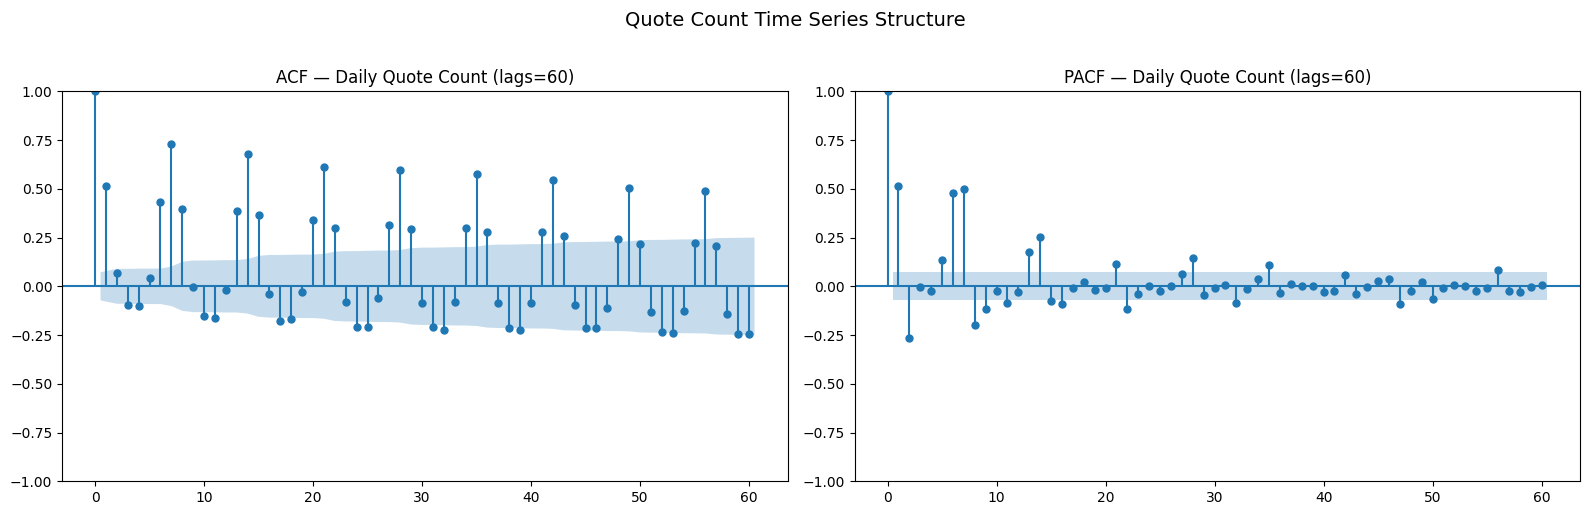

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

series = df_pd["daily_quote_count"].dropna()
sm.graphics.tsa.plot_acf(series, lags=60, ax=axes[0],
                          title="ACF — Daily Quote Count (lags=60)")
sm.graphics.tsa.plot_pacf(series, lags=60, ax=axes[1],
                           title="PACF — Daily Quote Count (lags=60)")

plt.suptitle("Quote Count Time Series Structure", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("../notebooks/acf_pacf_quotes.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# ── CORRECT quoteCountElasticity scatter ─────────────────────────
# Each point = one day (quote_date)
# X = that day's median yield
# Y = that day's quote count
# Question: on higher-yield days, do fewer quotes come in?

df_qc_scatter = df_daily_quotes.filter(
    pl.col("median_yield").is_not_null() &
    pl.col("median_yield").gt(5000) &
    pl.col("median_yield").lt(20000)
).to_pandas()

# bin into $500 yield brackets for smoother signal
df_qc_scatter["yield_bracket"] = (
    (df_qc_scatter["median_yield"] / 500).apply(int) * 500
)
df_qc_binned = (
    df_qc_scatter
    .groupby("yield_bracket")
    .agg(
        avg_daily_quote_count=("daily_quote_count", "mean"),
        n_days=("daily_quote_count", "count")
    )
    .reset_index()
    .query("n_days >= 3")   # min 3 days per bracket for stability
    .sort_values("yield_bracket")
)

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=df_qc_scatter["median_yield"],
    y=df_qc_scatter["daily_quote_count"],
    mode="markers", name="daily raw",
    marker=dict(color="#93c5fd", size=4, opacity=0.4)
))
fig.add_trace(go.Scatter(
    x=df_qc_binned["yield_bracket"],
    y=df_qc_binned["avg_daily_quote_count"],
    mode="lines+markers", name="bracket avg (smoothed signal)",
    line=dict(color="#2563eb", width=2.5),
    marker=dict(size=6)
))
fig.add_vline(
    x=10784, line_dash="dash", line_color="green",
    annotation_text="Y_median=$10,784"
)
fig.update_layout(
    title="quoteCountElasticity — Daily Quote Count vs Median Yield",
    xaxis_title="Median Yield ($/EFT hr)",
    yaxis_title="Daily Quote Count",
    **PLOT_CFG
)
fig.show()

In [21]:
# ── Load legs table to get revenue for confirmed quotes ───────────

# Load raw legs, filter NREG US, get revenue per LEG_ID
df_legs_raw = pl.read_csv(
    Path("../data/raw/legs_data_2024_2025_2026.csv"),
    try_parse_dates=False,
    infer_schema_length=10000
)

# ── Step 1: Build legs revenue lookup ─────────────────────────────
# Filter to Live + Landed + revenue > 0 only
df_legs_revenue = (
    df_legs_raw_sample
    .filter(
        pl.col("IS_FERRY").eq("Live") &
        pl.col("LEG_STATUS").eq("Landed") &
        pl.col("REVENUE").is_not_null() &
        pl.col("REVENUE").gt(0) &
        pl.col("FLEET_MODEL").is_in(["Challenger 300", "Challenger 350"])
    )
    .select([
        pl.col("ORDER_ID"),
        pl.col("DEPARTURE_ICAO").alias("dep_icao"),
        pl.col("ARRIVAL_ICAO").alias("arr_icao"),
        pl.col("REVENUE").alias("leg_revenue"),
        pl.col("ESTIMATED_FLIGHT_TIME").alias("leg_eft"),
    ])
    .with_columns(
        (pl.col("leg_revenue") / pl.col("leg_eft"))
          .alias("leg_yield")
    )
    .filter(pl.col("leg_yield").gt(1000))
)

print(f"Legs revenue lookup: {len(df_legs_revenue)} rows")

# ── Step 2: Prepare booked quotes for join ─────────────────────────
# Pull GV_ORDER_ID + route from the FILTERED (pre-dedup) table
# since dedup dropped GV_ORDER_ID
df_quote_order_map = (
    df_filtered
    .select([
        "QUOTE_LEG_ID",
        "GV_ORDER_ID",
        pl.col("DEP_ICAO_CD").alias("dep_icao"),
        pl.col("ARR_ICAO_CD").alias("arr_icao"),
    ])
    .unique(subset=["QUOTE_LEG_ID"])  # one row per quote
)

print(f"Quote order map: {len(df_quote_order_map)} rows")

# ── Step 3: Join on ORDER_ID + route ──────────────────────────────
df_yields_from_legs = (
    df_quote_order_map
    .join(
        df_legs_revenue,
        left_on=["GV_ORDER_ID", "dep_icao", "arr_icao"],
        right_on=["ORDER_ID", "dep_icao", "arr_icao"],
        how="inner"
    )
    .group_by("QUOTE_LEG_ID")
    .agg(
        pl.col("leg_yield").max().alias("leg_yield")  # take highest if multiple matches
    )
)

print(f"\nMatched quotes with leg yield: {len(df_yields_from_legs)}")
print(f"Yield stats:")
print(df_yields_from_legs["leg_yield"].describe())

# ── Step 4: Enrich deduped quotes ─────────────────────────────────
df_deduped_enriched = (
    df_deduped
    .join(df_yields_from_legs, on="QUOTE_LEG_ID", how="left")
    .with_columns(
        # booked=1 → use leg yield; booked=0 → use quoted yield
        pl.when(
            (pl.col("booked") == 1) & pl.col("leg_yield").is_not_null()
        ).then(pl.col("leg_yield"))
        .otherwise(pl.col("yield_per_eft"))
        .alias("final_yield")
    )
)

# Verify
booked_with_yield = df_deduped_enriched.filter(
    (pl.col("booked") == 1) & pl.col("final_yield").is_not_null()
)
booked_no_yield = df_deduped_enriched.filter(
    (pl.col("booked") == 1) & pl.col("final_yield").is_null()
)
print(f"\nBooked with yield:    {len(booked_with_yield)}")
print(f"Booked without yield: {len(booked_no_yield)}")
print(f"Recovery rate:        {len(booked_with_yield)/3860*100:.1f}%")

Legs revenue lookup: 27730 rows
Quote order map: 47400 rows

Matched quotes with leg yield: 2165
Yield stats:
shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 2165.0       │
│ null_count ┆ 0.0          │
│ mean       ┆ 8701.65517   │
│ std        ┆ 3809.222482  │
│ min        ┆ 1153.846154  │
│ 25%        ┆ 6432.0       │
│ 50%        ┆ 8247.580113  │
│ 75%        ┆ 10337.037037 │
│ max        ┆ 43914.285714 │
└────────────┴──────────────┘

Booked with yield:    2165
Booked without yield: 1695
Recovery rate:        56.1%


In [22]:
# ── Corrected conversionElasticity scatter ────────────────────────
df_elasticity = (
    df_deduped_enriched
    .filter(
        pl.col("final_yield").is_not_null() &
        pl.col("final_yield").gt(2000) &
        pl.col("final_yield").lt(30000)
    )
    .with_columns(
        ((pl.col("final_yield") / 500).floor() * 500)
          .alias("yield_bracket")
    )
)

df_conv_binned = (
    df_elasticity
    .group_by("yield_bracket")
    .agg([
        pl.len().alias("quote_count"),
        pl.col("booked").sum().alias("bookings"),
        pl.col("booked").mean().alias("conversion_rate"),
    ])
    .filter(pl.col("quote_count") >= 20)  # min 20 quotes for stability
    .sort("yield_bracket")
)

print("Conversion rate by yield bracket:")
print(df_conv_binned.select([
    "yield_bracket","quote_count","bookings","conversion_rate"
]))

df_conv_pd = df_conv_binned.to_pandas()

fig = make_subplots(rows=1, cols=2, subplot_titles=[
    "quoteCountElasticity — Daily Quote Count vs Yield",
    "conversionElasticity — Conversion Rate vs Yield"
])

# Chart 1: quote count (daily scatter + bracket avg)
df_qc = df_daily_quotes.filter(
    pl.col("median_yield").is_not_null() &
    pl.col("median_yield").gt(5000) &
    pl.col("median_yield").lt(20000)
).to_pandas()

df_qc["yield_bracket"] = (df_qc["median_yield"] / 500).astype(int) * 500
df_qc_binned = (
    df_qc.groupby("yield_bracket")
    .agg(avg_count=("daily_quote_count","mean"), n=("daily_quote_count","count"))
    .reset_index().query("n >= 3").sort_values("yield_bracket")
)

fig.add_trace(go.Scatter(
    x=df_qc["median_yield"], y=df_qc["daily_quote_count"],
    mode="markers", name="daily raw",
    marker=dict(color="#93c5fd", size=4, opacity=0.3)
), row=1, col=1)
fig.add_trace(go.Scatter(
    x=df_qc_binned["yield_bracket"], y=df_qc_binned["avg_count"],
    mode="lines+markers", name="bracket avg",
    line=dict(color="#2563eb", width=2.5)
), row=1, col=1)

# Chart 2: conversion rate
fig.add_trace(go.Scatter(
    x=df_conv_pd["yield_bracket"], y=df_conv_pd["conversion_rate"],
    mode="lines+markers", name="conversion rate",
    line=dict(color="#dc2626", width=2.5),
    marker=dict(size=6)
), row=1, col=2)

# median yield line on both
for col_idx in [1, 2]:
    fig.add_vline(
        x=10784, line_dash="dash", line_color="green",
        annotation_text="Y_median=$10,784",
        row=1, col=col_idx
    )

fig.update_layout(
    title="Corrected Elasticity Scatters — Quote Count + Conversion Rate vs Yield",
    height=550, width=1200,
    margin=dict(l=50, r=50, t=80, b=50),
    showlegend=False
)
fig.update_xaxes(title_text="Yield ($/EFT hr)")
fig.update_yaxes(title_text="Avg Daily Quote Count", row=1, col=1)
fig.update_yaxes(title_text="Conversion Rate", row=1, col=2)
fig.show()

# save enriched quotes
df_deduped_enriched.write_parquet(PROCESSED_DIR / "quotes_deduped_enriched.parquet")
print("\n✅ Saved → data/processed/quotes_deduped_enriched.parquet")

Conversion rate by yield bracket:
shape: (55, 4)
┌───────────────┬─────────────┬──────────┬─────────────────┐
│ yield_bracket ┆ quote_count ┆ bookings ┆ conversion_rate │
│ ---           ┆ ---         ┆ ---      ┆ ---             │
│ f64           ┆ u32         ┆ i64      ┆ f64             │
╞═══════════════╪═════════════╪══════════╪═════════════════╡
│ 2500.0        ┆ 33          ┆ 13       ┆ 0.393939        │
│ 3000.0        ┆ 45          ┆ 35       ┆ 0.777778        │
│ 3500.0        ┆ 75          ┆ 54       ┆ 0.72            │
│ 4000.0        ┆ 138         ┆ 100      ┆ 0.724638        │
│ 4500.0        ┆ 229         ┆ 68       ┆ 0.296943        │
│ …             ┆ …           ┆ …        ┆ …               │
│ 27500.0       ┆ 61          ┆ 0        ┆ 0.0             │
│ 28000.0       ┆ 70          ┆ 0        ┆ 0.0             │
│ 28500.0       ┆ 73          ┆ 1        ┆ 0.013699        │
│ 29000.0       ┆ 71          ┆ 0        ┆ 0.0             │
│ 29500.0       ┆ 65          ┆ 0   


✅ Saved → data/processed/quotes_deduped_enriched.parquet


In [23]:
# save deduplicated quote-level data
df_deduped.write_parquet(PROCESSED_DIR / "quotes_deduped.parquet")

# save daily quote count series
df_daily_quotes.write_parquet(PROCESSED_DIR / "quotes_fleet_daily.parquet")

print(f"✅ Saved → data/processed/quotes_deduped.parquet      ({len(df_deduped):,} unique quotes)")
print(f"✅ Saved → data/processed/quotes_fleet_daily.parquet  ({len(df_daily_quotes)} days)")

✅ Saved → data/processed/quotes_deduped.parquet      (47,400 unique quotes)
✅ Saved → data/processed/quotes_fleet_daily.parquet  (731 days)
